In [1]:
# Install dependencies if not already installed
%pip install -q numpy scipy soundfile matplotlib tqdm torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import platform
import subprocess
import torch

def get_cpu_info():
    try:
        if platform.system() == "Windows":
            import winreg
            key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
            name, _ = winreg.QueryValueEx(key, "ProcessorNameString")
            return name.strip()
        elif platform.system() == "Darwin":
            return subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip()
        elif platform.system() == "Linux":
            with open("/proc/cpuinfo", "r") as f:
                for line in f:
                    if "model name" in line:
                        return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or "CPU"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("OS:", platform.system(), platform.release())
print("CPU:", get_cpu_info(), f"({os.cpu_count()} cores)")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    vram = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"VRAM: {vram:.2f} GB")
else:
    print("GPU: None (using CPU)")

PyTorch version: 2.5.1+cu121
OS: Windows 11
CPU: 13th Gen Intel(R) Core(TM) i7-13650HX (20 cores)
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA version: 12.1
VRAM: 6.00 GB


In [3]:
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Audio configuration
SAMPLE_RATE = 16000
CHUNK_SECONDS = 2.0
CHUNK_SAMPLES = int(SAMPLE_RATE * CHUNK_SECONDS)

# STFT configuration
N_FFT = 512
HOP_LENGTH = 256
WINDOW = torch.hann_window(N_FFT).to(device)

# Training parameters
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
EPOCHS = 100
LEARNING_RATE = 1e-3
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 200

In [4]:
import os
import glob
import random
import soundfile as sf
import numpy as np
from scipy import signal
from torch.utils.data import Dataset, DataLoader

CLEAN_DIR = r"DNS-Challenge/datasets/clean/emotional_speech"
NOISE_DIR = r"DNS-Challenge/datasets/pure_noise"

def ensure_pure_noises():
    os.makedirs(NOISE_DIR, exist_ok=True)
    existing = glob.glob(os.path.join(NOISE_DIR, "*.wav"))
    if len(existing) >= 20:
        return existing
        
    print("Generating pure acoustic noise profiles (fans, AC, traffic, clicks, rumble)...")
    dur = 15.0
    nsamp = int(SAMPLE_RATE * dur)
    t = np.linspace(0, dur, nsamp, endpoint=False)
    
    # Fans & HVAC hum
    for i in range(10):
        white = np.random.normal(0, 1.0, nsamp)
        b, a = signal.butter(1, 0.05)
        pink = signal.lfilter(b, a, white)
        hum_freq = 50.0 if i % 2 == 0 else 60.0
        hum = 0.3 * np.sin(2 * np.pi * hum_freq * t) + 0.15 * np.sin(2 * np.pi * 2 * hum_freq * t)
        b_lp, a_lp = signal.butter(4, 1500 / (SAMPLE_RATE / 2), btype='low')
        noise = signal.lfilter(b_lp, a_lp, pink) + hum * 0.4
        noise = (noise / np.abs(noise).max() * 0.4).astype(np.float32)
        sf.write(os.path.join(NOISE_DIR, f"fan_hvac_{i:02d}.wav"), noise, SAMPLE_RATE)
        
    # Traffic & Car engine rumble
    for i in range(10):
        brownian = np.cumsum(np.random.normal(0, 1.0, nsamp))
        b_hp, a_hp = signal.butter(2, 30 / (SAMPLE_RATE / 2), btype='high')
        b_lp, a_lp = signal.butter(3, 800 / (SAMPLE_RATE / 2), btype='low')
        rumble = signal.lfilter(b_lp, a_lp, signal.lfilter(b_hp, a_hp, brownian))
        mod = 0.7 + 0.3 * np.sin(2 * np.pi * (0.2 + i * 0.05) * t)
        noise = (rumble * mod / np.abs(rumble).max() * 0.4).astype(np.float32)
        sf.write(os.path.join(NOISE_DIR, f"traffic_rumble_{i:02d}.wav"), noise, SAMPLE_RATE)
        
    # Typing & room clatter
    for i in range(10):
        bg = signal.lfilter(*signal.butter(2, 2000 / (SAMPLE_RATE / 2), btype='low'), np.random.normal(0, 0.05, nsamp))
        clicks = np.zeros(nsamp)
        idx_list = np.random.choice(nsamp - 500, size=int(dur * (5 + i * 2)), replace=False)
        for idx in idx_list:
            decay = np.exp(-np.linspace(0, 10, 300))
            clicks[idx : idx + 300] += np.random.normal(0, 0.4, 300) * decay
        noise = ((bg + clicks * 0.6) / np.abs(bg + clicks).max() * 0.4).astype(np.float32)
        sf.write(os.path.join(NOISE_DIR, f"office_clicks_{i:02d}.wav"), noise, SAMPLE_RATE)
        
    return glob.glob(os.path.join(NOISE_DIR, "*.wav"))

ensure_pure_noises()

clean_files = sorted(glob.glob(os.path.join(CLEAN_DIR, "**/*.wav"), recursive=True))
noise_files = sorted(glob.glob(os.path.join(NOISE_DIR, "**/*.wav"), recursive=True))

# Independent Train / Validation split (prevents data leakage and overfitting)
split_rng = random.Random(42)
split_rng.shuffle(clean_files)
split_rng.shuffle(noise_files)

train_clean, val_clean = clean_files[:4500], clean_files[4500:]
train_noise, val_noise = noise_files[:28], noise_files[28:]

print(f"Train set: {len(train_clean):,} clean files, {len(train_noise):,} noise files")
print(f"Val set  : {len(val_clean):,} clean files, {len(val_noise):,} noise files (unseen validation)")

def mix_audio(clean, noise, snr_db=5.0):
    clean_power = (clean ** 2).mean().clamp(min=1e-6)
    noise_power = (noise ** 2).mean().clamp(min=1e-6)
    target_noise_power = clean_power / (10 ** (snr_db / 10.0))
    scale = (target_noise_power / noise_power).sqrt()
    noisy = clean + scale * noise
    max_val = max(noisy.abs().max(), clean.abs().max(), 1e-4)
    if max_val > 0.95:
        noisy = noisy / max_val * 0.95
        clean = clean / max_val * 0.95
    return noisy, clean

class AudioDataset(Dataset):
    def __init__(self, clean_list, noise_list, length=2000, is_val=False):
        self.clean_list = clean_list
        self.noise_list = noise_list
        self.length = length
        self.is_val = is_val
        
        # Fixed benchmark pairs for validation to prevent random evaluation jitter
        if self.is_val:
            np_rng = np.random.RandomState(42)
            self.val_pairs = [
                (
                    self.clean_list[i % len(self.clean_list)],
                    self.noise_list[i % len(self.noise_list)],
                    float(np_rng.uniform(2.0, 12.0))
                )
                for i in range(length)
            ]
        
    def __len__(self):
        return self.length
        
    def _read_wav(self, path):
        data, _ = sf.read(path, dtype="float32")
        if data.ndim > 1:
            data = data.mean(axis=1)
        if len(data) < CHUNK_SAMPLES:
            data = np.pad(data, (0, CHUNK_SAMPLES - len(data)))
        elif len(data) > CHUNK_SAMPLES:
            idx = 0 if self.is_val else random.randint(0, len(data) - CHUNK_SAMPLES)
            data = data[idx : idx + CHUNK_SAMPLES]
        return torch.tensor(data, dtype=torch.float32)
        
    def __getitem__(self, idx):
        if self.is_val:
            c_path, n_path, snr = self.val_pairs[idx]
            clean = self._read_wav(c_path)
            noise = self._read_wav(n_path)
        else:
            clean = self._read_wav(random.choice(self.clean_list))
            noise = self._read_wav(random.choice(self.noise_list))
            snr = random.uniform(-2.0, 15.0)
            # Data augmentation: random volume gain jitter
            clean = clean * random.uniform(0.85, 1.15)
            
        noisy, clean = mix_audio(clean, noise, snr)
        return noisy, clean

train_loader = DataLoader(AudioDataset(train_clean, train_noise, TRAIN_SAMPLES, is_val=False), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(AudioDataset(val_clean, val_noise, VAL_SAMPLES, is_val=True), batch_size=BATCH_SIZE, shuffle=False)

Train set: 4,500 clean files, 28 noise files
Val set  : 560 clean files, 7 noise files (unseen validation)


In [5]:
import torch.nn as nn
import torch.nn.functional as F

class AudioEnhancer(nn.Module):
    def __init__(self, hidden_dim=128, dropout_rate=0.2):
        super().__init__()
        
        # Encoder with spatial dropout
        self.enc1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 1), padding=1),
            nn.BatchNorm2d(16),
            nn.LeakyReLU(0.2)
        )
        self.enc2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 1), padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            nn.Dropout2d(0.1)
        )
        self.enc3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 1), padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Dropout2d(0.15)
        )
        
        # Bottleneck RNN with recurrent dropout
        self.gru = nn.GRU(input_size=64 * 33, hidden_size=hidden_dim, num_layers=2, batch_first=True, dropout=dropout_rate)
        self.fc  = nn.Linear(hidden_dim, 64 * 33)
        
        # Decoder + skip connections
        self.dec3 = nn.Sequential(
            nn.ConvTranspose2d(64 + 64, 32, kernel_size=(3, 3), stride=(2, 1), padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            nn.Dropout2d(0.1)
        )
        self.dec2 = nn.Sequential(
            nn.ConvTranspose2d(32 + 32, 16, kernel_size=(3, 3), stride=(2, 1), padding=1),
            nn.BatchNorm2d(16),
            nn.LeakyReLU(0.2)
        )
        self.dec1 = nn.Sequential(
            nn.ConvTranspose2d(16 + 16, 1, kernel_size=(3, 3), stride=(2, 1), padding=1),
            nn.Sigmoid()
        )

    def forward(self, mag):
        x = mag.unsqueeze(1)
        
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        
        b, c, f, t = e3.shape
        gru_in = e3.permute(0, 3, 1, 2).reshape(b, t, c * f)
        gru_out, _ = self.gru(gru_in)
        gru_out = self.fc(gru_out)
        d_in = gru_out.reshape(b, t, c, f).permute(0, 2, 3, 1)
        
        d3 = self.dec3(torch.cat([d_in, e3], dim=1))
        d2 = self.dec2(torch.cat([d3, e2], dim=1))
        mask = self.dec1(torch.cat([d2, e1], dim=1))
        
        return mask.squeeze(1)

model = AudioEnhancer().to(device)
print(f"Model parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Model parameters: 1,302,481


In [6]:
import torch.optim as optim
import matplotlib.pyplot as plt

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-4)

def criterion(pred, target):
    l_lin = F.l1_loss(pred, target)
    l_log = F.l1_loss(torch.log1p(pred), torch.log1p(target))
    return l_lin + l_log

def train_epoch(model, loader, opt, win):
    model.train()
    running_loss = 0.0
    for noisy, clean in loader:
        noisy, clean = noisy.to(device), clean.to(device)
        
        n_stft = torch.stft(noisy, N_FFT, HOP_LENGTH, win_length=N_FFT, window=win, return_complex=True)
        c_stft = torch.stft(clean, N_FFT, HOP_LENGTH, win_length=N_FFT, window=win, return_complex=True)
        
        n_mag, c_mag = n_stft.abs(), c_stft.abs()
        
        mask = model(n_mag)
        enhanced_mag = n_mag * mask
        
        loss = criterion(enhanced_mag, c_mag)
        
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        opt.step()
        
        running_loss += loss.item()
    return running_loss / len(loader)

def validate(model, loader, win):
    model.eval()
    running_loss = 0.0
    with torch.no_grad():
        for noisy, clean in loader:
            noisy, clean = noisy.to(device), clean.to(device)
            
            n_stft = torch.stft(noisy, N_FFT, HOP_LENGTH, win_length=N_FFT, window=win, return_complex=True)
            c_stft = torch.stft(clean, N_FFT, HOP_LENGTH, win_length=N_FFT, window=win, return_complex=True)
            
            n_mag, c_mag = n_stft.abs(), c_stft.abs()
            
            mask = model(n_mag)
            enhanced_mag = n_mag * mask
            
            loss = criterion(enhanced_mag, c_mag)
            running_loss += loss.item()
    return running_loss / len(loader)

Training up to 100 epochs on cuda (Early Stopping patience: 12)...
Epoch 001/100 | Train Loss: 0.0766 | Val Loss: 0.0496 (saved best) | LR: 0.001000
Epoch 002/100 | Train Loss: 0.0570 | Val Loss: 0.0463 (saved best) | LR: 0.000999
Epoch 003/100 | Train Loss: 0.0528 | Val Loss: 0.0438 (saved best) | LR: 0.000998
Epoch 004/100 | Train Loss: 0.0506 | Val Loss: 0.0416 (saved best) | LR: 0.000996
Epoch 005/100 | Train Loss: 0.0509 | Val Loss: 0.0412 (saved best) | LR: 0.000994
Epoch 006/100 | Train Loss: 0.0483 | Val Loss: 0.0404 (saved best) | LR: 0.000992
Epoch 007/100 | Train Loss: 0.0496 | Val Loss: 0.0398 (saved best) | LR: 0.000989
Epoch 008/100 | Train Loss: 0.0479 | Val Loss: 0.0400 | LR: 0.000986
Epoch 009/100 | Train Loss: 0.0482 | Val Loss: 0.0403 | LR: 0.000982
Epoch 010/100 | Train Loss: 0.0470 | Val Loss: 0.0392 (saved best) | LR: 0.000978
Epoch 011/100 | Train Loss: 0.0477 | Val Loss: 0.0384 (saved best) | LR: 0.000973
Epoch 012/100 | Train Loss: 0.0458 | Val Loss: 0.0383 (sa

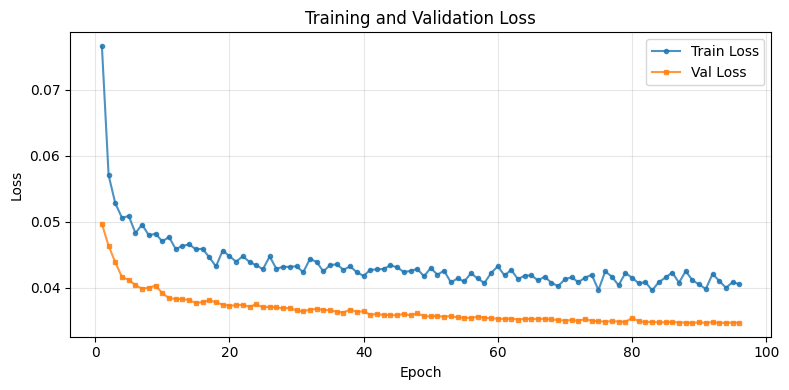

In [7]:
train_losses, val_losses = [], []
best_val_loss = float("inf")
patience = 12
patience_counter = 0

print(f"Training up to {EPOCHS} epochs on {device} (Early Stopping patience: {patience})...")
for epoch in range(1, EPOCHS + 1):
    tr_loss = train_epoch(model, train_loader, optimizer, WINDOW)
    va_loss = validate(model, val_loader, WINDOW)
    scheduler.step()
    
    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    
    if va_loss < best_val_loss - 1e-4:
        best_val_loss = va_loss
        patience_counter = 0
        torch.save(model.state_dict(), "audio_enhancer_model.pth")
        saved_mark = " (saved best)"
    else:
        patience_counter += 1
        saved_mark = ""
    
    print(f"Epoch {epoch:03d}/{EPOCHS:03d} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}{saved_mark} | LR: {scheduler.get_last_lr()[0]:.6f}")
    
    if patience_counter >= patience:
        print(f"\nEarly stopping at epoch {epoch}: Validation loss converged (no improvement for {patience} epochs).")
        break

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train Loss", marker="o", markersize=3, alpha=0.8)
plt.plot(range(1, len(val_losses) + 1), val_losses, label="Val Loss", marker="s", markersize=3, alpha=0.8)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Speech Enhancement Evaluation:
  Input Noisy SNR       : 5.75 dB
  Enhanced Output SNR   : 8.25 dB
  SNR Improvement       : +2.50 dB
  Noise Power Removed   : 43.8%



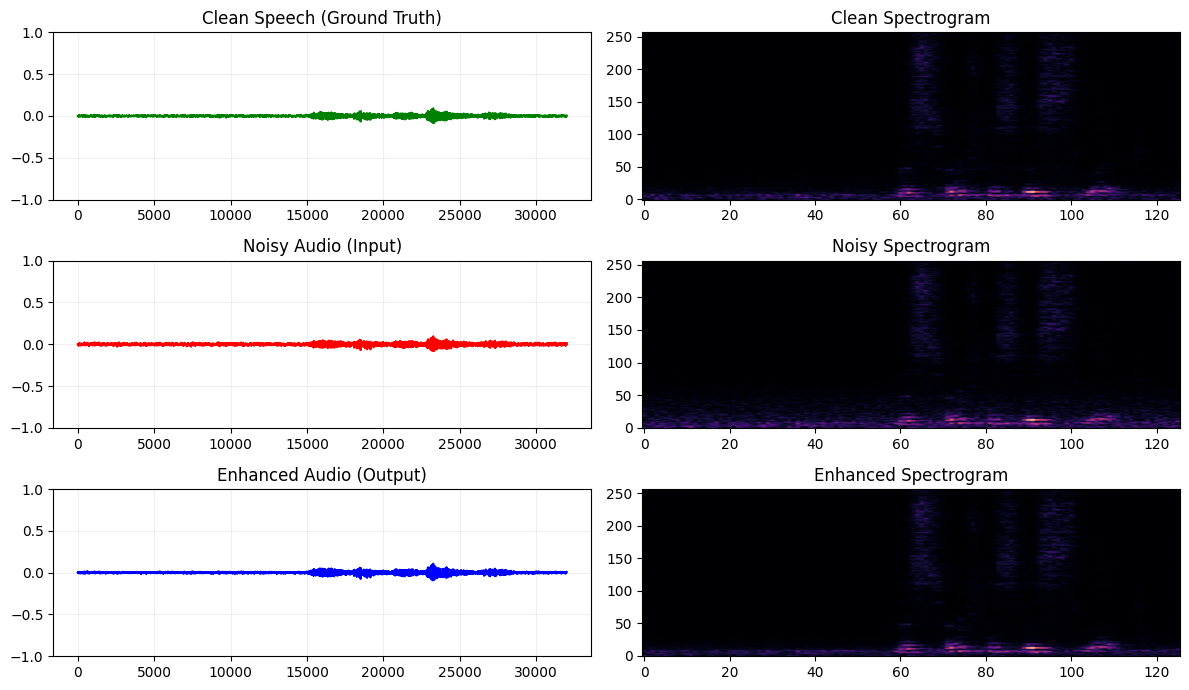

Clean Target:


Noisy Audio (Before):


Enhanced Audio (After):


In [8]:
from IPython.display import Audio, display

model.eval()
with torch.no_grad():
    noisy_batch, clean_batch = next(iter(val_loader))
    noisy_wav = noisy_batch[0:1].to(device)
    clean_wav = clean_batch[0:1].to(device)
    
    n_stft = torch.stft(noisy_wav, N_FFT, HOP_LENGTH, win_length=N_FFT, window=WINDOW, return_complex=True)
    n_mag = n_stft.abs()
    n_phase = n_stft.angle()
    
    mask = model(n_mag)
    enhanced_mag = n_mag * mask
    
    enh_stft = torch.polar(enhanced_mag, n_phase)
    enh_wav = torch.istft(enh_stft, N_FFT, HOP_LENGTH, win_length=N_FFT, window=WINDOW, length=CHUNK_SAMPLES)

clean_np = clean_wav.squeeze().cpu().numpy()
noisy_np = noisy_wav.squeeze().cpu().numpy()
enhanced_np = enh_wav.squeeze().cpu().numpy()

# Automatic Gain Control to restore natural speech volume
in_rms = np.sqrt(np.mean(noisy_np ** 2))
out_rms = np.sqrt(np.mean(enhanced_np ** 2))
if out_rms > 0:
    enhanced_np = enhanced_np * (in_rms / out_rms)
    if np.abs(enhanced_np).max() > 0.98:
        enhanced_np = enhanced_np / np.abs(enhanced_np).max() * 0.95

# Standard Speech Enhancement Metrics (SNR, Noise Power Reduction)
c_pow = np.mean(clean_np ** 2)
noisy_mse = np.mean((noisy_np - clean_np) ** 2)
enh_mse   = np.mean((enhanced_np - clean_np) ** 2)

noisy_snr = 10 * np.log10(c_pow / (noisy_mse + 1e-10))
enhanced_snr = 10 * np.log10(c_pow / (enh_mse + 1e-10))
snr_gain = enhanced_snr - noisy_snr
noise_reduction_pct = (1.0 - enh_mse / (noisy_mse + 1e-10)) * 100.0

print(f"Speech Enhancement Evaluation:")
print(f"  Input Noisy SNR       : {noisy_snr:.2f} dB")
print(f"  Enhanced Output SNR   : {enhanced_snr:.2f} dB")
print(f"  SNR Improvement       : +{snr_gain:.2f} dB")
print(f"  Noise Power Removed   : {noise_reduction_pct:.1f}%\n")

fig, axes = plt.subplots(3, 2, figsize=(12, 7))

# Waveforms
axes[0, 0].plot(clean_np, color="green")
axes[0, 0].set_title("Clean Speech (Ground Truth)")
axes[1, 0].plot(noisy_np, color="red")
axes[1, 0].set_title("Noisy Audio (Input)")
axes[2, 0].plot(enhanced_np, color="blue")
axes[2, 0].set_title("Enhanced Audio (Output)")

for ax in axes[:, 0]:
    ax.set_ylim(-1, 1)
    ax.grid(True, alpha=0.2)

# Spectrograms
c_stft = torch.stft(clean_wav, N_FFT, HOP_LENGTH, win_length=N_FFT, window=WINDOW, return_complex=True)
axes[0, 1].imshow(np.log1p(c_stft.abs()[0].cpu().numpy()), aspect="auto", origin="lower", cmap="magma")
axes[0, 1].set_title("Clean Spectrogram")

axes[1, 1].imshow(np.log1p(n_mag[0].cpu().numpy()), aspect="auto", origin="lower", cmap="magma")
axes[1, 1].set_title("Noisy Spectrogram")

axes[2, 1].imshow(np.log1p(enhanced_mag[0].cpu().numpy()), aspect="auto", origin="lower", cmap="magma")
axes[2, 1].set_title("Enhanced Spectrogram")

plt.tight_layout()
plt.show()

print("Clean Target:")
display(Audio(clean_np, rate=SAMPLE_RATE))

print("Noisy Audio (Before):")
display(Audio(noisy_np, rate=SAMPLE_RATE))

print("Enhanced Audio (After):")
display(Audio(enhanced_np, rate=SAMPLE_RATE))

In [9]:
def enhance_file(input_path, output_path, model, device, strength=1.1):
    model.eval()
    data, sr = sf.read(input_path, dtype="float32")
    if data.ndim > 1:
        data = data.mean(axis=1)
        
    # Resample to 16 kHz if necessary
    if sr != SAMPLE_RATE:
        num_target = int(len(data) * SAMPLE_RATE / sr)
        data = signal.resample(data, num_target)
        sr = SAMPLE_RATE
        
    wav = torch.tensor(data, dtype=torch.float32).unsqueeze(0).to(device)
    total_len = wav.shape[-1]
    win = torch.hann_window(N_FFT).to(device)
    
    with torch.no_grad():
        stft = torch.stft(wav, N_FFT, HOP_LENGTH, win_length=N_FFT, window=win, return_complex=True)
        mag = stft.abs()
        phase = stft.angle()
        
        mask = model(mag)
        if strength != 1.0:
            mask = mask ** strength
        enh_mag = mag * mask
        
        enh_stft = torch.polar(enh_mag, phase)
        enh_wav = torch.istft(enh_stft, N_FFT, HOP_LENGTH, win_length=N_FFT, window=win, length=total_len)
        
    out = enh_wav.squeeze().cpu().numpy()
    
    # Gain normalization
    in_rms = np.sqrt(np.mean(data ** 2))
    out_rms = np.sqrt(np.mean(out ** 2))
    if out_rms > 0:
        out = out * (in_rms / out_rms)
        if np.abs(out).max() > 0.98:
            out = out / np.abs(out).max() * 0.95
            
    sf.write(output_path, out, sr)
    print(f"Enhanced: {input_path} -> Saved: {output_path}")
    return out

# Denoise a test file
test_files = glob.glob(r"DNS-Challenge/datasets/pure_noise/*.wav")
clean_test = glob.glob(r"DNS-Challenge/datasets/clean/emotional_speech/**/*.wav", recursive=True)
if test_files and clean_test:
    # Create realistic noisy test recording
    c_data, _ = sf.read(clean_test[0], dtype="float32")
    n_data, _ = sf.read(test_files[0], dtype="float32")
    min_len = min(len(c_data), len(n_data), SAMPLE_RATE * 5)
    sample_noisy, _ = mix_audio(torch.tensor(c_data[:min_len]), torch.tensor(n_data[:min_len]), snr_db=5.0)
    sf.write("sample_noisy_input.wav", sample_noisy.numpy(), SAMPLE_RATE)
    enhanced_audio = enhance_file("sample_noisy_input.wav", "sample_enhanced_output.wav", model, device)
    
    print("Enhanced Test Output:")
    display(Audio("sample_enhanced_output.wav"))

Enhanced: sample_noisy_input.wav -> Saved: sample_enhanced_output.wav
Enhanced Test Output:


In [10]:
torch.save(model.state_dict(), "audio_enhancer_model.pth")
print("Saved model checkpoint to audio_enhancer_model.pth")

Saved model checkpoint to audio_enhancer_model.pth
